In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    ConfusionMatrixDisplay
)

print("Machine learning libraries are ready!")

Machine learning libraries are ready!


In [2]:
np.random.seed(42)

n = 200

df = pd.DataFrame({
    "Distance_km": np.random.randint(5, 1000, n),
    "Order_Units": np.random.randint(1, 50, n),
    "Warehouse_Load": np.random.randint(20, 101, n),
    "Shipping_Method": np.random.choice(
        ["Standard", "Express"], n
    )
})

delay_score = (
    (df["Distance_km"] > 600).astype(int)
    + (df["Warehouse_Load"] > 80).astype(int)
    + (df["Shipping_Method"] == "Standard").astype(int)
)

df["Delayed"] = (delay_score >= 2).astype(int)

df.head(10)

,Distance_km,Order_Units,Warehouse_Load,Shipping_Method,Delayed
0,107,30,49,Standard,0
1,440,37,65,Express,0
2,865,23,25,Express,0
3,275,39,56,Standard,0
4,111,45,43,Express,0
5,76,15,65,Standard,0
6,705,43,72,Express,0
7,25,29,79,Standard,0
8,619,36,82,Standard,1
9,126,13,51,Standard,0


In [3]:
print("Dataset shape:", df.shape)

print("\nFirst 5 rows:")
display(df.head())

print("\nDelay counts:")
print(df["Delayed"].value_counts())

print("\nMissing values:")
print(df.isnull().sum())

Dataset shape: (200, 5)

First 5 rows:


,Distance_km,Order_Units,Warehouse_Load,Shipping_Method,Delayed
0,107,30,49,Standard,0
1,440,37,65,Express,0
2,865,23,25,Express,0
3,275,39,56,Standard,0
4,111,45,43,Express,0



Delay counts:
Delayed
0    137
1     63
Name: count, dtype: int64

Missing values:
Distance_km        0
Order_Units        0
Warehouse_Load     0
Shipping_Method    0
Delayed            0
dtype: int64


In [4]:
# Convert Shipping_Method into numerical columns
df = pd.get_dummies(
    df,
    columns=["Shipping_Method"],
    dtype=int
)

# Display the updated dataset
display(df.head())

print("Updated dataset shape:", df.shape)
print("\nColumn names:")
print(df.columns.tolist())

,Distance_km,Order_Units,Warehouse_Load,Delayed,Shipping_Method_Express,Shipping_Method_Standard
0,107,30,49,0,0,1
1,440,37,65,0,1,0
2,865,23,25,0,1,0
3,275,39,56,0,0,1
4,111,45,43,0,1,0


Updated dataset shape: (200, 6)

Column names:
['Distance_km', 'Order_Units', 'Warehouse_Load', 'Delayed', 'Shipping_Method_Express', 'Shipping_Method_Standard']


In [5]:
# Separate input features (X) and target (y)
X = df.drop("Delayed", axis=1)
y = df["Delayed"]

# Split the data: 80% training, 20% testing
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)

print("Training target:", y_train.shape)
print("Testing target:", y_test.shape)

Training data: (160, 5)
Testing data: (40, 5)
Training target: (160,)
Testing target: (40,)


In [6]:
# Create the Decision Tree model
model = DecisionTreeClassifier(
    max_depth=5,
    random_state=42
)

# Train the model using training data
model.fit(X_train, y_train)

print("Decision Tree model trained successfully!")

Decision Tree model trained successfully!


In [7]:
# Predict outcomes for the testing data
y_pred = model.predict(X_test)

# Compare actual and predicted results
results = X_test.copy()
results["Actual_Delayed"] = y_test
results["Predicted_Delayed"] = y_pred

display(results.head(10))

,Distance_km,Order_Units,Warehouse_Load,Shipping_Method_Express,Shipping_Method_Standard,Actual_Delayed,Predicted_Delayed
51,567,12,82,1,0,0,1
18,668,28,43,1,0,0,0
52,880,39,70,0,1,1,1
143,396,36,62,0,1,0,0
118,883,16,52,0,1,1,1
37,861,27,79,1,0,0,0
86,936,16,81,1,0,1,1
150,235,35,62,0,1,0,0
8,619,36,82,0,1,1,1
181,771,45,31,0,1,1,1


In [8]:
# Calculate prediction accuracy
accuracy = accuracy_score(y_test, y_pred)

print(f"Model Accuracy: {accuracy * 100:.2f}%")

# Show detailed performance metrics
print("\nClassification Report:")
print(classification_report(
    y_test,
    y_pred,
    target_names=["Not Delayed", "Delayed"],
    zero_division=0
))

Model Accuracy: 97.50%

Classification Report:
              precision    recall  f1-score   support

 Not Delayed       1.00      0.96      0.98        27
     Delayed       0.93      1.00      0.96        13

    accuracy                           0.97        40
   macro avg       0.96      0.98      0.97        40
weighted avg       0.98      0.97      0.98        40



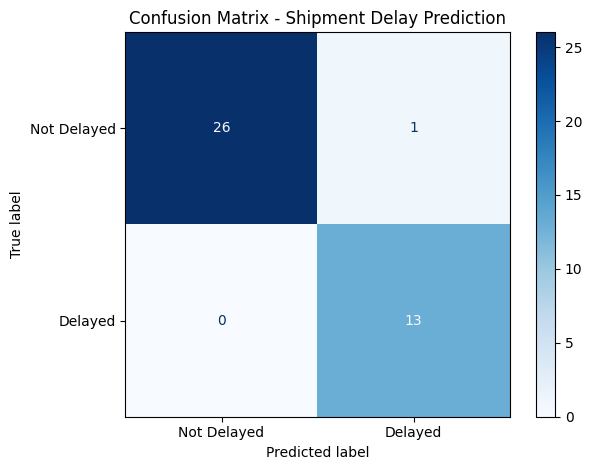

In [9]:
# Create the confusion matrix visualization
ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_pred,
    display_labels=["Not Delayed", "Delayed"],
    cmap="Blues"
)

plt.title("Confusion Matrix - Shipment Delay Prediction")
plt.tight_layout()
plt.show()

,Feature,Importance
4,Shipping_Method_Standard,0.376471
2,Warehouse_Load,0.328003
0,Distance_km,0.295527
1,Order_Units,0.000000
3,Shipping_Method_Express,0.000000


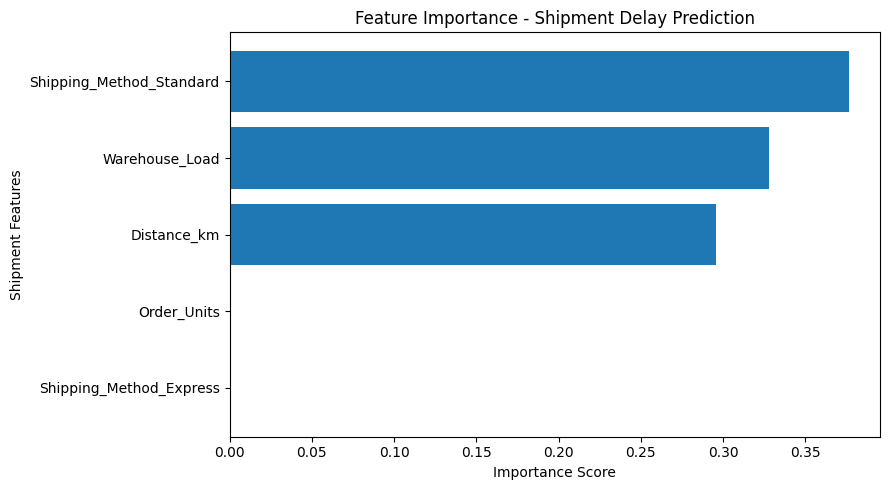

In [10]:
# Get feature importance scores from the trained model
importance = pd.DataFrame({
    "Feature": X_train.columns,
    "Importance": model.feature_importances_
})

# Sort from highest to lowest
importance = importance.sort_values(
    by="Importance",
    ascending=False
)

# Display the importance values
display(importance)

# Create a bar chart
plt.figure(figsize=(9, 5))
plt.barh(
    importance["Feature"],
    importance["Importance"]
)

plt.xlabel("Importance Score")
plt.ylabel("Shipment Features")
plt.title("Feature Importance - Shipment Delay Prediction")
plt.gca().invert_yaxis()
plt.tight_layout()
plt.show()

In [11]:
# Save actual and predicted shipment outcomes
results.to_csv("shipment_prediction_results.csv", index=False)

print("Prediction results saved successfully!")

Prediction results saved successfully!


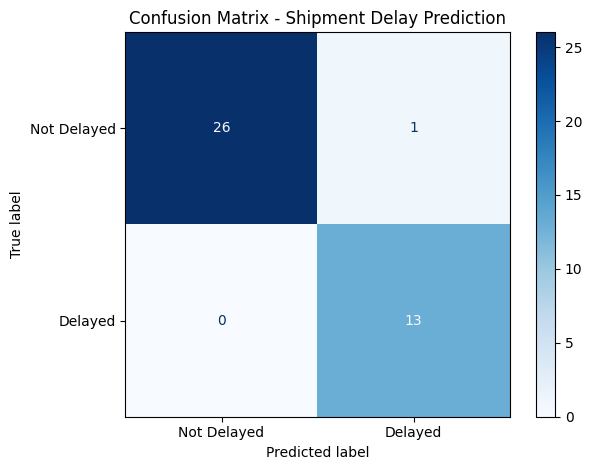

In [12]:
# Save the confusion matrix
ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_pred,
    display_labels=["Not Delayed", "Delayed"],
    cmap="Blues"
)

plt.title("Confusion Matrix - Shipment Delay Prediction")
plt.tight_layout()
plt.savefig("confusion_matrix.png", dpi=300, bbox_inches="tight")
plt.show()

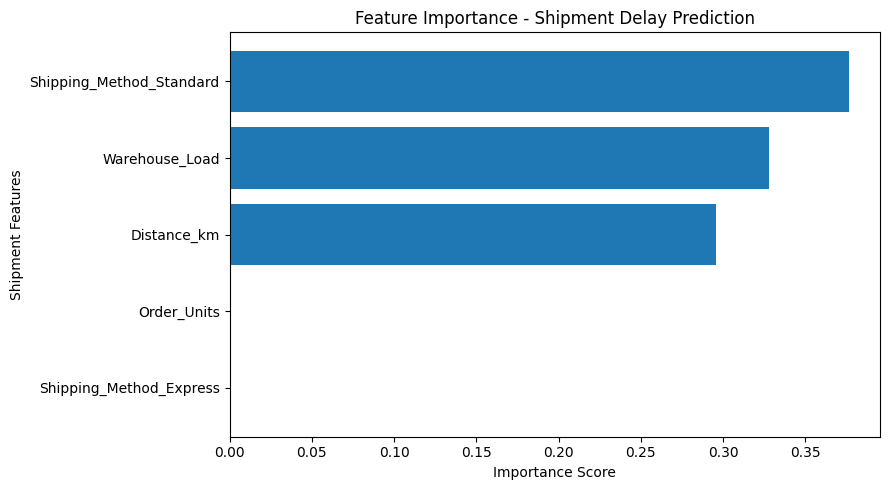

In [13]:
plt.figure(figsize=(9, 5))
plt.barh(importance["Feature"], importance["Importance"])
plt.xlabel("Importance Score")
plt.ylabel("Shipment Features")
plt.title("Feature Importance - Shipment Delay Prediction")
plt.gca().invert_yaxis()
plt.tight_layout()

plt.savefig("feature_importance.png", dpi=300, bbox_inches="tight")
plt.show()

In [14]:
# Create a business insights report

accuracy_percent = accuracy * 100

report = f"""
LOGISTICS PREDICTIVE MODELING
Shipment Delay Prediction Using Machine Learning

1. PROJECT OBJECTIVE
The objective is to build a supervised machine learning model
to predict whether a shipment will be delayed.

2. DATASET
- Total simulated shipments: {len(df)}
- Input features: {X.shape[1]}
- Target variable: Delayed
- 0 = Not Delayed
- 1 = Delayed

3. METHODOLOGY
- Created a simulated logistics dataset using Python.
- Converted shipping method categories into numerical features.
- Split the data into 80% training and 20% testing.
- Trained a Decision Tree Classifier.
- Evaluated predictions using accuracy and a classification report.

4. MODEL PERFORMANCE
- Model accuracy: {accuracy_percent:.2f}%

5. BUSINESS INSIGHTS
This model demonstrates how shipment distance, warehouse workload,
order units and shipping method can be used as input features
for predicting delivery delays.

Feature importance indicates which inputs the model relied on
most when making predictions.

6. RECOMMENDATIONS
- Monitor shipments with a higher predicted risk of delay.
- Review warehouse workload and long-distance shipments.
- Track delay patterns using actual operational data.
- Retrain and validate the model using real historical shipments.

7. LIMITATIONS
This project uses simulated data and rule-generated delay labels.
The accuracy does not establish real-world predictive performance.
Real logistics data and further validation are needed before
using this model for operational decisions.

Tools: Python, Pandas, NumPy, Matplotlib and Scikit-learn.
"""

with open("Business_Insights_Report.txt", "w", encoding="utf-8") as file:
    file.write(report)

print(report)
print("\nBusiness insights report saved successfully!")


LOGISTICS PREDICTIVE MODELING
Shipment Delay Prediction Using Machine Learning

1. PROJECT OBJECTIVE
The objective is to build a supervised machine learning model
to predict whether a shipment will be delayed.

2. DATASET
- Total simulated shipments: 200
- Input features: 5
- Target variable: Delayed
- 0 = Not Delayed
- 1 = Delayed

3. METHODOLOGY
- Created a simulated logistics dataset using Python.
- Converted shipping method categories into numerical features.
- Split the data into 80% training and 20% testing.
- Trained a Decision Tree Classifier.
- Evaluated predictions using accuracy and a classification report.

4. MODEL PERFORMANCE
- Model accuracy: 97.50%

5. BUSINESS INSIGHTS
This model demonstrates how shipment distance, warehouse workload,
order units and shipping method can be used as input features
for predicting delivery delays.

Feature importance indicates which inputs the model relied on
most when making predictions.

6. RECOMMENDATIONS
- Monitor shipments with a hig